# 04 · Cleaning — step by step

This notebook runs the cleaning **one step at a time** so you can see what changes.
It uses the same functions as `src/04_clean.py` (they live in `src/cleaning.py`), so the
notebook and the script always give the same result.

**Rule: flag, don't delete.** Dropping a scientist also drops their links and changes the
network. So we only remove pages that are not about one scientist. Everything else stays,
with True/False columns, and each analysis filters on those.

**End product** (in `data/clean/`):

| File | What |
|---|---|
| `nodes_clean.csv` | one row per scientist: the table everyone uses |
| `edges_clean.csv` | links between the scientists we kept |
| `dropped_nodes.csv` | the few pages removed, and why |
| `cleaning_log.md` | counts after every step, for Methods |

Two files in `data/manual/` are filled in **by hand** (created the first time, never overwritten):
`hand_check_matches.csv` (is the OpenAlex profile the right person?) and `birth_year_fixes.csv`.
After filling them in, re-run this notebook or `python src/04_clean.py`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))   # run from project/notebooks/
import cleaning as C

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

## 0 · Raw data (the snapshot from the collection scripts)

In [2]:
nodes_raw, edges_raw, impact_raw = C.load_raw()
print(f"nodes.csv : {len(nodes_raw):>6,} scientists")
print(f"edges.csv : {len(edges_raw):>6,} links between them")
print(f"impact.csv: {len(impact_raw):>6,} people looked up in OpenAlex "
      f"({impact_raw.cited_by_count.notna().sum():,} matched)")
nodes_raw.head(3)

nodes.csv :  9,857 scientists
edges.csv : 10,645 links between them
impact.csv:  3,161 people looked up in OpenAlex (3,060 matched)


,qid,title,gender,birth_year,fields,orcid,openalex_id,birth_year_conflict,wiki_title,n_chars,n_words,n_links_total,revid,rev_timestamp
0,Q100210668,Boris Kayser,male,1938,physicist,0000-0001-8640-0053,NaN,False,Boris Kayser,2688,434,30,1334308627,2026-01-22T19:33:52Z
1,Q100212,Peter Kramer (physicist),male,1933,physicist,NaN,NaN,False,Peter Kramer (physicist),1401,224,26,1356714829,2026-05-29T11:25:05Z
2,Q100216,Willi A. Kalender,male,1949,physicist,NaN,NaN,False,Willi A. Kalender,4894,725,36,1291667780,2025-05-22T17:40:43Z


## 1 · Gender → male / female / other

Wikidata's gender (P21) is kept as `gender_raw`. Anyone not recorded as only male or only
female becomes `other`: they **stay in the network** (removing them would cut their links)
but are left out of the women-vs-men comparisons (`gender_binary = False`).

In [3]:
nodes = C.clean_gender(nodes_raw)
display(pd.crosstab(nodes.gender_raw, nodes.gender))
nodes.loc[nodes.gender == "other", ["qid", "title", "gender_raw", "birth_year", "fields"]]

gender,female,male,other
gender_raw,,,
Q113124952,0,0,1
female,1473,0,0
male,0,8377,0
multiple,0,0,3
non-binary,0,0,1
trans man,0,0,1
trans woman,0,0,1


,qid,title,gender_raw,birth_year,fields
770,Q115804793,John Thorp (researcher),trans man,1927,chemist
1863,Q15983297,Devendra Lal,multiple,1929,physicist
1871,Q15990211,Rachael Padman,trans woman,1954,physicist
4502,Q29840061,Dagmar Ringe,multiple,1942,chemist
5392,Q42207726,A. W. Peet,multiple,1950,physicist
5612,Q443431,Karen Barad,non-binary,1956,physicist
8122,Q68016365,Greg Gbur,Q113124952,1971,physicist


## 2 · Drop pages that are not about one scientist

* Several people pointing to the **same** Wikipedia page (a family page, the Bogdanoff twins'
  shared page): the text and the links aren't about that person.
* Pages with **no text** at all: these are soft redirects to Wikispecies.

In [4]:
nodes, dropped = C.drop_invalid_pages(nodes)
lost = edges_raw.source_qid.isin(dropped.qid) | edges_raw.target_qid.isin(dropped.qid)
print(f"dropped {len(dropped)} pages -> {len(nodes):,} scientists left; "
      f"{lost.sum()} links touched these pages")
dropped

dropped 6 pages -> 9,851 scientists left; 23 links touched these pages


,qid,title,wiki_title,gender,n_words,reason
1205,Q13415350,Ulrich Merkel,Family of Angela Merkel,male,612,page shared by several people / about someone ...
2608,Q18618827,Igor Bogdanoff,Igor and Grichka Bogdanoff,male,2518,page shared by several people / about someone ...
2609,Q18618829,Grichka Bogdanoff,Igor and Grichka Bogdanoff,male,2518,page shared by several people / about someone ...
3301,Q21337735,Sven Bradler,Sven Bradler,male,0,no article text (soft redirect)
3460,Q22109612,Richard van der Laan,Richard van der Laan,male,0,no article text (soft redirect)
6864,Q56119579,Marcus Kasner,Family of Angela Merkel,male,612,page shared by several people / about someone ...


## 3 · Birth year, decade, field, short pages

* **Birth year conflicts:** 14 people have two birth years on Wikidata. The collection script
  kept the earlier one. Check them by hand in `data/manual/birth_year_fixes.csv`.
* **Birth decade** is used to compare people of the same generation. 1980 goes in the 1970s bin.
* **Stubs:** pages under 50 words are kept but flagged (`is_stub`); the text analysis skips them.

In [5]:
fixes = C.read_manual(C.BIRTH_FIX_FILE)
if fixes is None:
    print("No birth_year_fixes.csv yet - this is what it will contain:")
    fixes_view = C.birth_fix_template(nodes)
else:
    print(f"{fixes.birth_year_fixed.notna().sum()} of {len(fixes)} filled in")
    fixes_view = fixes
display(fixes_view)

nodes = C.apply_birth_fixes(nodes, fixes)
nodes = C.add_field_and_stub(nodes)
pd.crosstab(nodes.birth_decade, nodes.gender, margins=True)

No birth_year_fixes.csv yet - this is what it will contain:


,qid,title,birth_year_used,years_on_wikidata,birth_year_fixed,source_note
1063,Q126846,Spartak Belyaev,1921,1921;1923,<NA>,
1237,Q1349224,William J. Nellis,1941,1941;1943,<NA>,
1539,Q15059118,Tomas Ganz,1948,1948;1953,<NA>,
1721,Q1554056,Guillermo Soberón Acevedo,1925,1925;1929,<NA>,
1857,Q15971746,Denis Le Bihan,1947,1947;1957,<NA>,
2875,Q19871496,Rod Boswell,1932,1932;1944,<NA>,
4169,Q28030687,Leslie Bretherick,1924,1924;1926,<NA>,
4522,Q29933248,Boris Shraiman,1950,1950;1956,<NA>,
7033,Q56949313,Laurette Tuckerman,1956,1956;1976,<NA>,
7518,Q61825174,Fang Fukang,1935,1935;1946,<NA>,


gender,female,male,other,All
birth_decade,,,,
1920,178,1731,2,1911
1930,171,1864,0,2035
1940,239,1942,1,2182
1950,320,1456,3,1779
1960,290,951,0,1241
1970,275,427,1,703
All,1473,8371,7,9851


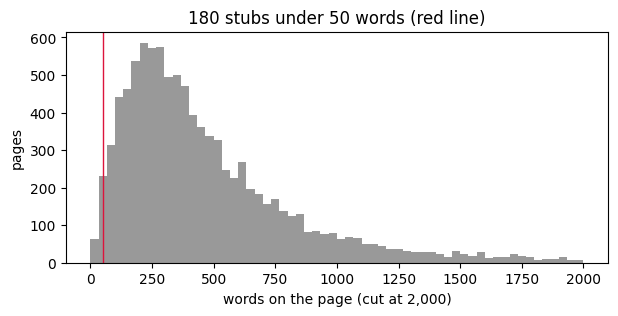

gender,female,male,other,All
field,,,,
both,29,188,0,217
chemistry,636,2678,2,3316
physics,808,5505,5,6318
All,1473,8371,7,9851


In [6]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(nodes.n_words.clip(lower=1), bins=60, log=False,
        range=(0, 2000), color="0.6")
ax.axvline(C.STUB_WORDS, color="crimson", lw=1)
ax.set_xlabel("words on the page (cut at 2,000)"); ax.set_ylabel("pages")
ax.set_title(f"{nodes.is_stub.sum()} stubs under {C.STUB_WORDS} words (red line)")
plt.show()
pd.crosstab(nodes.field, nodes.gender, margins=True)

## 4 · Impact (OpenAlex)

Impact data only exists for people with an ORCID or OpenAlex ID on Wikidata.
The coverage depends strongly on **birth decade** — so women and men must be compared within
the same decade.

n       with_impact       share      
gender       female  male      female male female  male
birth_decade                                           
1920            178  1731           4   22   0.02  0.01
1930            171  1864          12  181   0.07  0.10
1940            239  1942          58  608   0.24  0.31
1950            320  1456         163  751   0.51  0.52
1960            290   951         193  589   0.67  0.62
1970            275   427         205  270   0.75  0.63

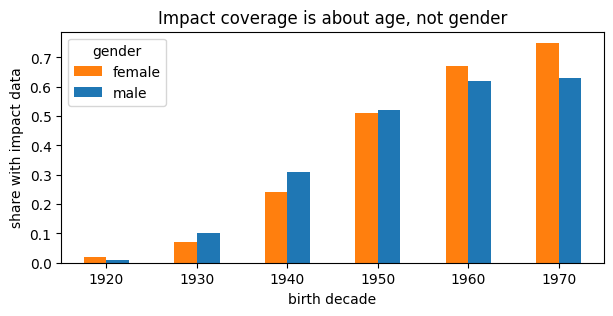

In [7]:
nodes = C.merge_impact(nodes, impact_raw)
cov = C.coverage_table(nodes, "birth_decade")
display(cov)

share = cov["share"]
share.plot(kind="bar", figsize=(7, 3), color=["tab:orange", "tab:blue"])
plt.ylabel("share with impact data"); plt.xlabel("birth decade"); plt.xticks(rotation=0)
plt.title("Impact coverage is about age, not gender"); plt.show()

### Suspicious OpenAlex profiles

Profiles with more than 2,000 works are usually several people merged together, data-set
deposits counted as papers, or huge particle-physics collaborations. They're flagged
(`suspect_profile`) and left out of the main analysis; robustness checks can put them back.

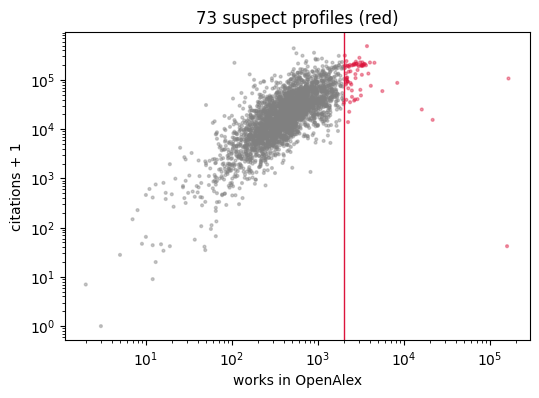

,title,oa_display_name,works_count,cited_by_count,h_index,top_field
8548,Richard D. Smith,Richard D. Smith,164258.0,107054.0,157.0,Chemistry
9476,Peter Murray-Rust,Peter Murray-Rust,158002.0,41.0,4.0,Computer Science
7066,Henry Rzepa,Henry S. Rzepa,21574.0,15453.0,60.0,Physics and Astronomy
5459,Julia Laskin,Julia Laskin,16116.0,25119.0,83.0,Chemistry
5976,Arnold L. Rheingold,Arnold L. Rheingold,8361.0,87113.0,116.0,Chemistry
3241,Alexandra Slawin,Alexandra M. Z. Slawin,5610.0,59378.0,109.0,Chemistry
7960,Arie Bodek,A. Bodek,4538.0,223215.0,204.0,Physics and Astronomy
7725,Judith Howard,Judith A. K. Howard,4122.0,75985.0,85.0,Chemistry
4681,Gautier Hamel de Monchenault,G. Hamel de Monchenault,4027.0,225862.0,199.0,Physics and Astronomy
305,Thomas Henning,Thomas K. Henning,3858.0,134664.0,159.0,Physics and Astronomy


In [8]:
m = nodes[nodes.has_impact]
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(m.works_count, m.cited_by_count + 1, s=4, alpha=0.4,
           c=m.suspect_profile.map({True: "crimson", False: "0.5"}))
ax.axvline(C.SUSPECT_WORKS, color="crimson", lw=1)
ax.set(xscale="log", yscale="log", xlabel="works in OpenAlex", ylabel="citations + 1",
       title=f"{m.suspect_profile.sum()} suspect profiles (red)")
plt.show()
m[m.suspect_profile].nlargest(10, "works_count")[
    ["title", "oa_display_name", "works_count", "cited_by_count", "h_index", "top_field"]]

### Hand check: is the OpenAlex profile the right person?

The sample is every match with a low or unknown name similarity (different alphabet,
married name, nickname...) plus 85 random matches, half women. Open both links and write
`ok`, `wrong` or `unsure` in the `verdict` column of `data/manual/hand_check_matches.csv`.

A `wrong` match keeps the person in the network but empties their impact columns.
The share of `ok` matches (by gender) goes in Methods.

In [9]:
checks = C.read_manual(C.HAND_CHECK_FILE)
if checks is None:
    print("No hand_check_matches.csv yet - this is the sample it will contain:")
    checks_view = C.hand_check_template(nodes)
else:
    filled = checks.verdict.fillna("").str.strip().ne("")
    print(f"{filled.sum()} of {len(checks)} verdicts filled in")
    checks_view = checks
display(pd.crosstab(checks_view.why_checked, checks_view.gender, margins=True))
checks_view.head(10)[["wiki_title", "oa_display_name", "name_similarity",
                      "last_institution", "verdict"]]

No hand_check_matches.csv yet - this is the sample it will contain:


gender,female,male,All
why_checked,,,
low or unknown name similarity,6,10,16
random sample,42,43,85
All,48,53,101


,wiki_title,oa_display_name,name_similarity,last_institution,verdict
0,Thunderf00t,Philip E. Mason,0.087,Czech Academy of Sciences,
1,Artem Oganov,Артем Ромаевич Оганов,NaN,Skolkovo Institute of Science and Technology,
2,Viktor Maslov (mathematician),Виктор Павлович Маслов,NaN,Ivanovo State University,
3,Gennady Gorelik,Геннадий Ефимович Горелик,NaN,Boston University,
4,Lev Zelyony,H. V. Malova,0.286,Russian Academy of Sciences,
5,Leonid Yatsenko,Леонід Петрович Яценко,NaN,National Academy of Sciences of Ukraine,
6,Nathalie Palanque-Delabrouille,N. Palanque‐Delabrouille,0.462,Boston University,
7,Debra Bernhardt,Debra J. Searles,0.333,The University of Queensland,
8,Renata Kallosh,Рената Каллош,NaN,Stanford University,
9,Ayana Holloway Arce,A. T. H. Arce,0.414,Duke University,


In [10]:
nodes = C.apply_hand_check(nodes, checks)
nodes = C.add_impact_measures(nodes)
hc = C.hand_check_summary(nodes)
hc if not hc.empty else "no verdicts yet"

'no verdicts yet'

## 5 · Main analysis set and citation bins

The **main set** = male or female, has impact data, not a wrong match, not a suspect profile.
Citation quintiles are computed once on that set, pooled over women and men (so bin 5 is the
same citation range for both).

Check the cell counts: the comparisons are *within quintile × birth decade*, so small cells
(few women in old, highly cited bins) are where results get shaky.

In [11]:
main = nodes[nodes.in_main_set]
print(f"main set: {len(main):,} scientists "
      f"({(main.gender == 'female').sum()} women, {(main.gender == 'male').sum()} men)")
display(main.groupby("citation_quintile").cited_by_count.agg(["min", "median", "max"]).astype(int))
print("Women per citation quintile x birth decade:")
pd.crosstab(main[main.gender == "female"].birth_decade,
            main[main.gender == "female"].citation_quintile, margins=True)

main set: 2,983 scientists (623 women, 2360 men)


,min,median,max
citation_quintile,,,
1,0,3699,6896
2,6904,10068,14195
3,14207,19140,25265
4,25279,33585,45408
5,45511,69282,439057


Women per citation quintile x birth decade:


citation_quintile,1,2,3,4,5,All
birth_decade,,,,,,
1920,2,1,0,1,0,4
1930,4,3,2,2,0,11
1940,14,18,7,7,9,55
1950,35,42,45,21,15,158
1960,56,44,38,29,24,191
1970,71,56,43,17,17,204
All,182,164,135,77,65,623


## 6 · Links and degrees

Links touching dropped pages go; in-degree and out-degree are counted on what's left.
Network measures (Afonso) use **all** scientists and links, not only the main set.

In [12]:
edges = C.clean_edges(edges_raw, nodes)
nodes = C.add_degrees(nodes, edges)
print(f"links: {len(edges_raw):,} -> {len(edges):,}")
nodes[nodes.gender_binary].groupby("gender").agg(
    scientists=("qid", "size"),
    share_in_degree_0=("in_degree", lambda s: round((s == 0).mean(), 2)),
    mean_in_degree=("in_degree", "mean"),
    max_in_degree=("in_degree", "max")).round(2)

links: 10,645 -> 10,622


,scientists,share_in_degree_0,mean_in_degree,max_in_degree
gender,,,,
female,1473,0.73,0.48,23
male,8371,0.57,1.18,60


In [13]:
# First look (no null model!): mean in-degree by citation quintile, main set only
main = nodes[nodes.in_main_set]
main.pivot_table(index="citation_quintile", columns="gender",
                 values="in_degree", aggfunc="mean").round(2)

gender,female,male
citation_quintile,,
1,0.37,0.72
2,0.44,0.77
3,0.59,1.15
4,0.70,1.71
5,1.08,2.64


## 7 · Write the clean files

`run_all()` repeats exactly the steps above and writes `data/clean/`. The first time, it
also creates the two files in `data/manual/` for you to fill in.

In [14]:
res = C.run_all(write=True)
for step, n, note in res["log"]:
    print(f"{step:<32} {n:>6,}   {note}")

Created data/manual/birth_year_fixes.csv - fill in birth_year_fixed
Created data/manual/hand_check_matches.csv - fill in verdict


Wrote data/clean/ (9851 nodes, 10622 edges)
raw nodes.csv                     9,857   10645 edges
gender -> male/female/other       9,857   7 'other' kept, not compared
drop shared/empty pages           9,851   6 dropped
birth decade, field, stubs        9,851   0 of 14 birth-year conflicts fixed by hand; 180 stubs (<50 words)
impact merged + hand check        9,851   3058 with impact; 0 checked, 0 wrong; 73 suspect profiles (> 2000 works)
edges between kept nodes          9,851   10622 edges
main analysis set                 2,983   623 women, 2360 men


In [15]:
clean = pd.read_csv(C.CLEAN / "nodes_clean.csv")
print(clean.shape)
clean.head()

(9851, 32)


,qid,title,wiki_title,revid,gender,gender_raw,gender_binary,birth_year,birth_year_conflict,birth_year_fixed_by_hand,birth_decade,field,n_words,is_stub,in_degree,out_degree,has_impact,match_method,n_openalex_profiles,openalex_id,oa_display_name,name_similarity,match_checked,match_ok,suspect_profile,works_count,cited_by_count,log_citations,h_index,citation_quintile,top_field,in_main_set
0,Q100210668,Boris Kayser,Boris Kayser,1334308627,male,male,True,1938,False,False,1930,physics,434,False,0,3,True,orcid,1.0,A5106074093,Boris J. Kayser,0.923,False,NaN,False,193.0,8691.0,3.939120,36.0,2.0,Physics and Astronomy,True
1,Q100212,Peter Kramer (physicist),Peter Kramer (physicist),1356714829,male,male,True,1933,False,False,1930,physics,224,False,0,2,False,NaN,NaN,NaN,NaN,NaN,False,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,Q100216,Willi A. Kalender,Willi A. Kalender,1291667780,male,male,True,1949,False,False,1940,physics,725,False,0,0,False,NaN,NaN,NaN,NaN,NaN,False,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,Q1002250,Duncan Haldane,Duncan Haldane,1382342840,male,male,True,1951,False,False,1950,physics,593,False,7,4,True,orcid,1.0,A5089213304,F. D. M. Haldane,0.667,False,NaN,False,235.0,42531.0,4.628716,70.0,4.0,Physics and Astronomy,True
4,Q100235232,Joseph Johnson III,Joseph Johnson III,1372410899,male,male,True,1940,False,False,1940,physics,451,False,0,1,False,NaN,NaN,NaN,NaN,NaN,False,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


### Columns of `nodes_clean.csv`

| Group | Columns |
|---|---|
| who | `qid` (key to everything), `title`, `wiki_title`, `revid` (exact page version) |
| groups | `gender` (male/female/other), `gender_raw`, `gender_binary`, `birth_year`, `birth_year_conflict`, `birth_year_fixed_by_hand`, `birth_decade`, `field` (physics/chemistry/both) |
| page | `n_words`, `is_stub` |
| network | `in_degree`, `out_degree` (PageRank and the extra visibility measures get added later) |
| impact | `has_impact`, `match_method`, `n_openalex_profiles`, `openalex_id`, `oa_display_name`, `name_similarity`, `match_checked`, `match_ok`, `suspect_profile`, `works_count`, `cited_by_count`, `log_citations`, `h_index`, `citation_quintile`, `top_field` |
| filter | `in_main_set` |

**Which rows to use**
* Network measures → all rows of `nodes_clean.csv` + `edges_clean.csv`
* Women vs men at equal impact (RQ1, RQ2) → `in_main_set == True`
* Text analysis → `in_main_set == True` and `is_stub == False`